In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
print("Libraries Imported")

Libraries Imported


In [ ]:
# Load the new dataset
df_adm = pd.read_csv('/content/adm_data.csv')
print('Admission Dataset reading complete')

Admission Dataset reading complete


In [ ]:
# Display the first 5 rows of the new dataset
df_adm.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [ ]:
# Display the last 5 rows of the new dataset
df_adm.tail()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
395,396,324,110,3,3.5,3.5,9.04,1,0.82
396,397,325,107,3,3.0,3.5,9.11,1,0.84
397,398,330,116,4,5.0,4.5,9.45,1,0.91
398,399,312,103,3,3.5,4.0,8.78,0,0.67
399,400,333,117,4,5.0,4.0,9.66,1,0.95


In [ ]:
# Display the shape of the new dataset
df_adm.shape

(400, 9)

In [ ]:
# Display descriptive statistics of the new dataset
df_adm.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,200.500000,316.807500,107.410000,3.087500,3.400000,3.452500,8.598925,0.547500,0.724350
std,115.614301,11.473646,6.069514,1.143728,1.006869,0.898478,0.596317,0.498362,0.142609
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.000000,6.800000,0.000000,0.340000
25%,100.750000,308.000000,103.000000,2.000000,2.500000,3.000000,8.170000,0.000000,0.640000
50%,200.500000,317.000000,107.000000,3.000000,3.500000,3.500000,8.610000,1.000000,0.730000
75%,300.250000,325.000000,112.000000,4.000000,4.000000,4.000000,9.062500,1.000000,0.830000
max,400.000000,340.000000,120.000000,5.000000,5.000000,5.000000,9.920000,1.000000,0.970000


In [ ]:
# Duplicates finding
df_adm.duplicated().sum()

np.int64(0)

In [ ]:
# Display information about the new dataset (data types, non-null counts)
df_adm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         400 non-null    int64  
 1   GRE Score          400 non-null    int64  
 2   TOEFL Score        400 non-null    int64  
 3   University Rating  400 non-null    int64  
 4   SOP                400 non-null    float64
 5   LOR                400 non-null    float64
 6   CGPA               400 non-null    float64
 7   Research           400 non-null    int64  
 8   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 28.3 KB


In [ ]:
# Check for null values in the new dataset
df_adm.isnull().sum()

,0
Serial No.,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,0
Chance of Admit,0


In [ ]:
# Find categorical columns
cat_cols = df_adm.select_dtypes(include=['object']).columns

print("Categorical Columns:", list(cat_cols))

# Apply lable Encoding
le = LabelEncoder()

for col in cat_cols:
    df_adm[col] = le.fit_transform(df_adm[col])

print("adm Encoding Completed")
display(df_adm.head())

Categorical Columns: []
adm Encoding Completed


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [ ]:
# Numerical columns
numeric_cols = df_adm.select_dtypes(include=np.number).columns

Q1 = df_adm[numeric_cols].quantile(0.25)
Q3 = df_adm[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

outliers = ((df_adm[numeric_cols] < (Q1 - 1.5 * IQR)) |
            (df_adm[numeric_cols] > (Q3 + 1.5 * IQR)))

print("Number of Outliers in each column:")
print(outliers.sum())

Number of Outliers in each column:
Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  1
CGPA                 1
Research             0
Chance of Admit      2
dtype: int64


In [ ]:
# Create cleaned dataset
print("Original Shape :", df_adm.shape)
df_adm = df_adm[~((df_adm[numeric_cols] < (Q1 - 1.5 * IQR)) |
                    (df_adm[numeric_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]
print("After Removing Outliers :", df_adm.shape)

Original Shape : (400, 9)
After Removing Outliers : (396, 9)


In [ ]:
# Define independent and dependent variables for adm_data
# Drop 'Serial No.' as it's an identifier and 'Chance of Admit' is the target
x_adm = df_adm.drop(['Serial No.', 'Chance of Admit '], axis=1) # Note the space in 'Chance of Admit '
y_adm = df_adm['Chance of Admit ']

print('Independent variables (x_adm):')
display(x_adm.head())
print('\nDependent variable (y_adm):')
display(y_adm.head())

Independent variables (x_adm):


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
0,337,118,4,4.5,4.5,9.65,1
1,324,107,4,4.0,4.5,8.87,1
2,316,104,3,3.0,3.5,8.00,1
3,322,110,3,3.5,2.5,8.67,1
4,314,103,2,2.0,3.0,8.21,0



Dependent variable (y_adm):


,Chance of Admit
0,0.92
1,0.76
2,0.72
3,0.80
4,0.65


In [ ]:
# Perform one-hot encoding on 'University Rating' column
x_adm_encoded = pd.get_dummies(x_adm, columns=['University Rating'], drop_first=True)

print('Shape of x_adm before encoding:', x_adm.shape)
print('Shape of x_adm after encoding:', x_adm_encoded.shape)

display(x_adm_encoded.head())

Shape of x_adm before encoding: (396, 7)
Shape of x_adm after encoding: (396, 10)


,GRE Score,TOEFL Score,SOP,LOR,CGPA,Research,University Rating_2,University Rating_3,University Rating_4,University Rating_5
0,337,118,4.5,4.5,9.65,1,False,False,True,False
1,324,107,4.0,4.5,8.87,1,False,False,True,False
2,316,104,3.0,3.5,8.00,1,False,True,False,False
3,322,110,3.5,2.5,8.67,1,False,True,False,False
4,314,103,2.0,3.0,8.21,0,True,False,False,False


In [ ]:
# Split the new dataset into training and testing sets
x_adm_train, x_adm_test, y_adm_train, y_adm_test = train_test_split(x_adm_encoded, y_adm, test_size=0.2, random_state=42)
print('Admission dataset split into training and testing sets using one-hot encoded features.')

Admission dataset split into training and testing sets using one-hot encoded features.


In [ ]:
# Create and train a Linear Regression model for the admission data
model_adm = LinearRegression()
model_adm.fit(x_adm_train, y_adm_train)
print('Linear Regression Model for Admission Data Trained.')

Linear Regression Model for Admission Data Trained.


In [ ]:
# Generate predictions for training and testing datasets using the trained admission model
y_adm_train_pred = model_adm.predict(x_adm_train)
y_adm_test_pred = model_adm.predict(x_adm_test)
print('Predictions Generated for both training and testing sets of Admission Data.')

Predictions Generated for both training and testing sets of Admission Data.


In [ ]:
# Display the intercept of the admission model
print('Intercept for Admission Model:')
model_adm.intercept_

Intercept for Admission Model:


np.float64(-1.0804795355805676)

In [ ]:
# Evaluate the admission model using different evaluation metrics
print('Model Evaluation Metrics for Admission Data (Training Set):')
mae_adm_train = mean_absolute_error(y_adm_train, y_adm_train_pred)
mse_adm_train = mean_squared_error(y_adm_train, y_adm_train_pred)
rmse_adm_train = np.sqrt(mse_adm_train)
r2_adm_train = r2_score(y_adm_train, y_adm_train_pred)
print(f'Mean Absolute Error (MAE): {mae_adm_train:.4f}')
print(f'Mean Squared Error (MSE): {mse_adm_train:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse_adm_train:.4f}')
print(f'R2 Score: {r2_adm_train:.4f}')

Model Evaluation Metrics for Admission Data (Training Set):
Mean Absolute Error (MAE): 0.0429
Mean Squared Error (MSE): 0.0036
Root Mean Squared Error (RMSE): 0.0602
R2 Score: 0.7988


In [ ]:
# Evaluate the admission model using different evaluation metrics
print('\nModel Evaluation Metrics for Admission Data (Test Set):')
mae_adm_test = mean_absolute_error(y_adm_test, y_adm_test_pred)
mse_adm_test = mean_squared_error(y_adm_test, y_adm_test_pred)
rmse_adm_test = np.sqrt(mse_adm_test)
r2_adm_test = r2_score(y_adm_test, y_adm_test_pred)
print(f'Mean Absolute Error (MAE): {mae_adm_test:.4f}')
print(f'Mean Squared Error (MSE): {mse_adm_test:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse_adm_test:.4f}')
print(f'R2 Score: {r2_adm_test:.4f}')


Model Evaluation Metrics for Admission Data (Test Set):
Mean Absolute Error (MAE): 0.0496
Mean Squared Error (MSE): 0.0047
Root Mean Squared Error (RMSE): 0.0683
R2 Score: 0.7997


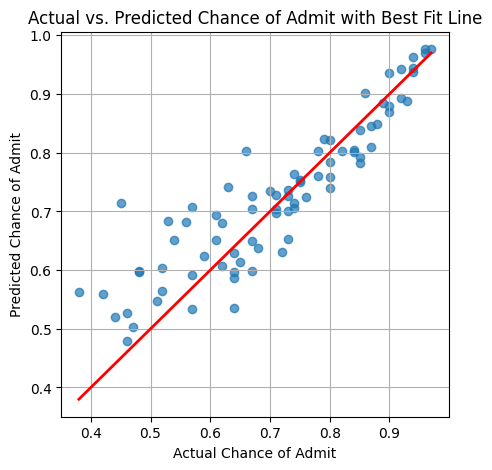

In [ ]:
plt.figure(figsize=(5, 5))
plt.scatter(y_adm_test, y_adm_test_pred, alpha=0.7)
plt.plot([y_adm_test.min(), y_adm_test.max()], [y_adm_test.min(), y_adm_test.max()], 'r-', lw=2)
plt.xlabel('Actual Chance of Admit')
plt.ylabel('Predicted Chance of Admit')
plt.title('Actual vs. Predicted Chance of Admit with Best Fit Line')
plt.grid(True)
plt.show()